# Soot Modeling Example

_This demo is part of Spitfire, with [licensing and copyright info here.](https://github.com/sandialabs/Spitfire/blob/master/license.md)_


_Highlights_

- Tabulating and plotting soot source term coefficients
- Tabulating and plotting soot radiation and absorption coefficients
- Tabulating and plotting gas radiation and absorption coefficients
- Comparing soot models along particle trajectories

In this demo, we build a nonadiabatic flamelet library then add coefficients relevant to soot modeling and absorption/radiation. The different model forms are shown in the soot modeling documentation. We then demonstrate how these libraries might be analyzed for use in simulation with soot transport.


## The nonadiabatic flamelet library
First we'll build a flamelet library for an n-heptane/air system. We are using the liu-C7 mechanism, which limits the soot modeling to Aksit Moss since there is no benzene present. The higher fidelity caltech mechanism incorporates benzene, but takes longer to run.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from spitfire import build_nonadiabatic_defect_transient_slfm_library, ChemicalMechanismSpec, odesolve, PIController
from spitfire import get_soot_source_term_evaluator, get_soot_source_term_jacobian_evaluator, tabulate_gas_radiation_model, tabulate_soot_radiation_model, tabulate_soot_source_coefficients
from spitfire.data.get import datafile


In [2]:
mech = ChemicalMechanismSpec(cantera_input=datafile('liu-C7.yaml'), group_name='gas')
pressure = 101325.
air = mech.stream(stp_air=True)
air.TP = 300., pressure
fuel = mech.stream('TPY', (500., pressure, 'NXC7H16:1'))
flamelet_specs = {'mech_spec': mech,
                  'oxy_stream': air,
                  'fuel_stream': fuel,
                  'grid_points': 81}
chivals = np.logspace(-2,0,4)


In [3]:
lib = build_nonadiabatic_defect_transient_slfm_library(flamelet_specs, chivals)

----------------------------------------------------------------------------------
building nonadiabatic (defect) SLFM library
----------------------------------------------------------------------------------
- mechanism: /ascldap/users/earmstr/.conda/envs/spclone2/lib/python3.11/site-packages/spitfire/data/liu-C7.yaml
- 38 species, 105 reactions
- stoichiometric mixture fraction: 0.062
----------------------------------------------------------------------------------
----------------------------------------------------------------------------------
building adiabatic SLFM library
----------------------------------------------------------------------------------
- mechanism: cantera-input-not-given
- 38 species, 105 reactions
- stoichiometric mixture fraction: 0.062
----------------------------------------------------------------------------------
   1/   4 (chi_stoich =  1.0e-02 1/s)  converged in   2.57 s, T_max = 2234.0
   2/   4 (chi_stoich =  4.6e-02 1/s)  converged in   0.08 s, 

## Gas Radiation Model

Now we tabulate gas absorption (`gas_abs_coeff`) and radiation (`gas_rad_source`) coefficients. The absorption coefficient has units (1/m) and the radiation coefficient has units $(\mathrm{W}/\mathrm{m}^3)$.

The default model is `Barlow_GreyGas`, whose equations are outlined in the soot modeling documentation. Below we are plotting the coefficients over mixture fraction and all stoichiometric enthalpy defects for a single stoichiometric dissipation rate.

In [4]:
lib = tabulate_gas_radiation_model(mech, lib, modelname='Barlow_GreyGas')


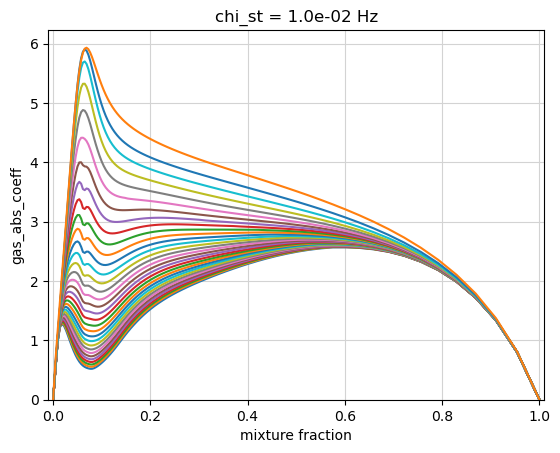

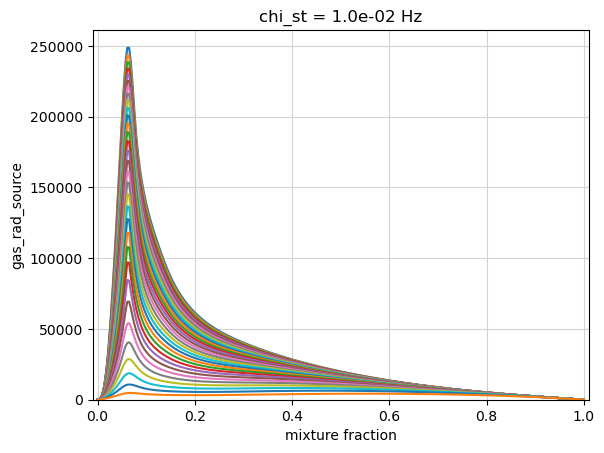

In [5]:
chi_index = 0
for prop in ['gas_abs_coeff','gas_rad_source']:
    plt.plot(lib.mixture_fraction_values, lib[prop][:,chi_index,:])
    plt.grid(color='lightgray')
    plt.ylabel(prop)
    plt.xlabel('mixture fraction')
    plt.title(f'chi_st = {lib.dissipation_rate_stoich_values[chi_index]:.1e} Hz')
    plt.xlim([-0.01,1.01])
    plt.ylim(bottom=0.)
    plt.show()


## Soot Radiation Model

Next we show how to tabulate soot absorption (`soot_abs_coeff`) and radiation (`soot_rad_source`) coefficients. The absorption coefficient has units (1/m) and the radiation coefficient has units $(\mathrm{W}/\mathrm{m}^3)$.

The default model is `linear_absorption_coefficient`, whose equations are outlined in the soot modeling documentation. This model takes parameters for the linear slope, intercept, and minimum value, for which we are using default values. Below we plot the coefficients over mixture fraction and all stoichiometric enthalpy defects for a single stoichiometric dissipation rate.

In [6]:
lib = tabulate_soot_radiation_model(mech, lib, modelname='linear_absorption_coefficient')


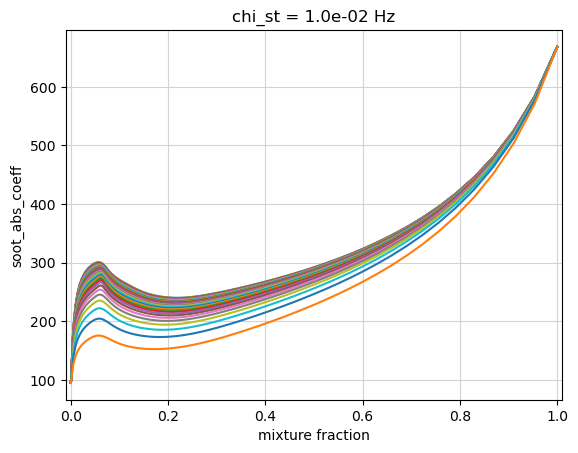

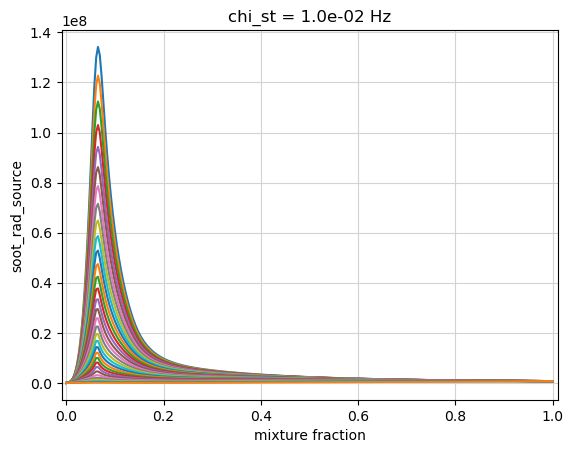

In [7]:
chi_index = 0
for prop in ['soot_abs_coeff','soot_rad_source']:
    plt.plot(lib.mixture_fraction_values, lib[prop][:,chi_index,:])
    plt.grid(color='lightgray')
    plt.ylabel(prop)
    plt.xlabel('mixture fraction')
    plt.title(f'chi_st = {lib.dissipation_rate_stoich_values[chi_index]:.1e} Hz')
    plt.xlim([-0.01,1.01])
    plt.show()


## Soot Source Coefficient Model

Supported soot models include: `Aksit_Moss`, `Aksit_Moss_Benzene`, and `PAH_alpha`. The mechanism we used for this demo does not have benzene, so we will stick with `Aksit_Moss`. All model equations are shown in the soot documentation.

Running `tabulate_soot_source_coefficients` adds relevant coefficients for nucleation, coagulation, condensation, surface growth, and surface oxidation to the library. You can also specify a `soot_leakage_fraction` which controls the amount of soot allowed to "leak" into fuel-lean regions of the flame, accounting for finite-rate oxidation. This is based on a sub-filter model for soot oxidation, where 0% leakage corresponds to infinitely fast oxidation (not allowing soot to be present near the oxidizer stream) and larger leakage rates limit that oxidation. Using 0.>=`soot_leakage_fraction`>1. adds a 'soot_subfilter' property to the library, showing the function with which the surface growth and oxidation terms get multiplied.

Below we compare the 'Aksit_Moss' coefficients with 100% and 1% soot leakage. Nucleation and coagulation are identical between the two libraries. The surface growth and oxidation coefficients have been modified for the smaller leakage, seen more dramatically in the oxidation coefficients. The 1% leakage limits the amount of soot present for lean mixtures, assuming it gets oxidized faster than the original library. Therefore, the oxidation coefficients for the 1% leakage library are smaller in those lean regions compared to the original 100% leakage library.

Units are as follows:

- surface growth and oxidation ('surf_'): $\mathrm{kg}^{4/3} \mathrm{m}^{-3} \mathrm{s}^{-1} \mathrm{kmol}^{-1/3}$

- nucleation ('nucl_'): $\mathrm{kmol}^{1} \mathrm{m}^{-3} \mathrm{s}^{-1}$

- coagulation ('coag'): $\mathrm{kg}^{11/6} \mathrm{m}^{-3} \mathrm{s}^{-1} \mathrm{kmol}^{-5/6}$


In [8]:
soot_model = 'Aksit_Moss'
lib_p0 = tabulate_soot_source_coefficients(mech, lib, soot_model)
lib_p1 = tabulate_soot_source_coefficients(mech, lib, soot_model, soot_leakage_fraction=0.01)


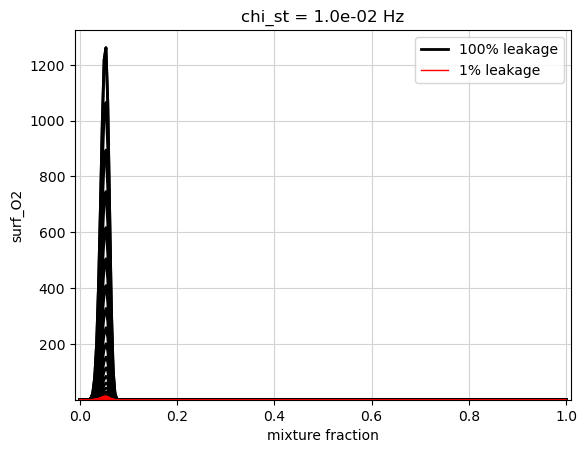

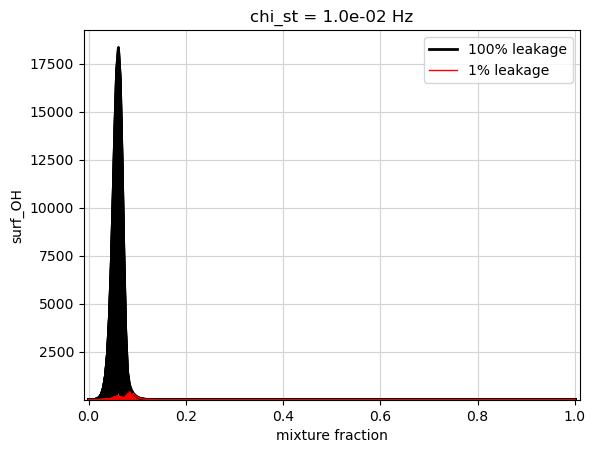

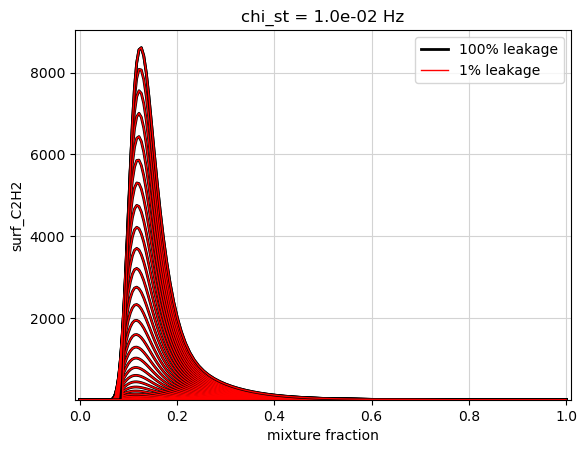

In [9]:
logscale = False
chi_index = 0

colors = ['k','r']
for prop in ['surf_O2', 'surf_OH', 'surf_C2H2']:
    lp0 = lib_p0[prop][:,chi_index,:]
    lp1 = lib_p1[prop][:,chi_index,:]

    plt.plot(lib_p0.mixture_fraction_values, lp0, '-', color=colors[0], linewidth=2)
    plt.plot(lib_p1.mixture_fraction_values, lp1, '-', color=colors[1], linewidth=1)
    #for legend...
    plt.plot(lib_p0.mixture_fraction_values, lp0[:,0], '-', color=colors[0], linewidth=2, label='100% leakage')
    plt.plot(lib_p1.mixture_fraction_values, lp1[:,0], '-', color=colors[1], linewidth=1, label=f'1% leakage')

    plt.grid(color='lightgray')
    if logscale:
        plt.yscale('log')
    plt.ylim(bottom=1.e-4)
    plt.title(f'chi_st = {lib.dissipation_rate_stoich_values[chi_index]:.1e} Hz')
    plt.xlim([-0.01,1.01])
    plt.ylabel(prop)
    plt.xlabel('mixture fraction')
    plt.legend()
    plt.show()


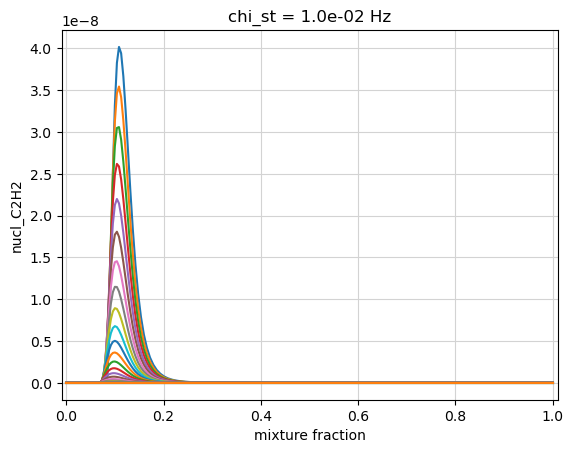

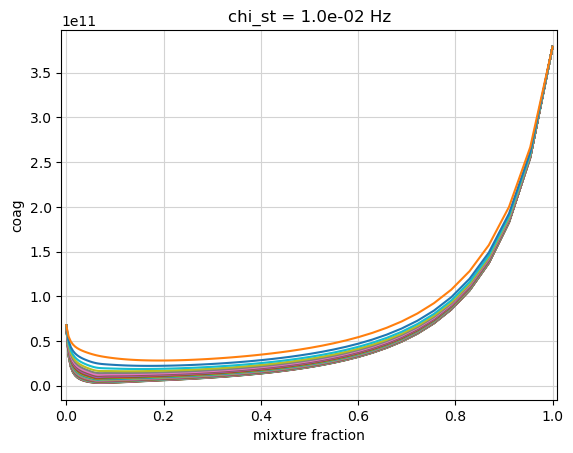

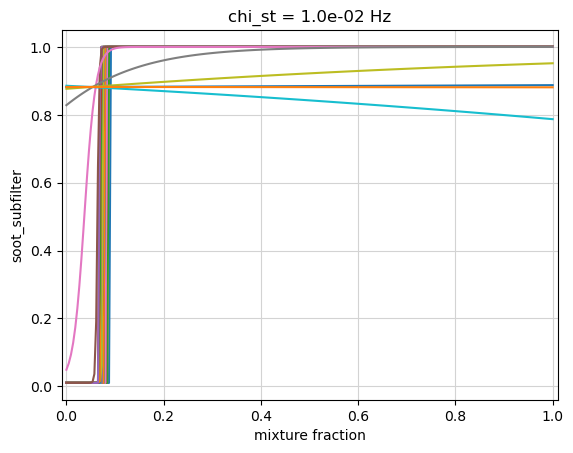

In [10]:
chi_index = 0
for prop in ['nucl_C2H2','coag','soot_subfilter']:
    plt.plot(lib_p1.mixture_fraction_values, lib_p1[prop][:,chi_index,:])
    plt.grid(color='lightgray')
    plt.ylabel(prop)
    plt.xlabel('mixture fraction')
    plt.title(f'chi_st = {lib_p1.dissipation_rate_stoich_values[chi_index]:.1e} Hz')
    plt.xlim([-0.01,1.01])
    plt.show()


## Comparing Soot Models for Transport

Once we have tabulated all relevant soot and radiation coefficients, our library is ready to use in simulation for a sooting fire that transports a soot mass fraction (unitless) and soot number density (kmol soot / kg air). 

If we have simulation data available from transporting soot, we can use it to perform a sensitivity analysis on the soot levels with respect to the flamelet model.
For example, we can estimate the change in soot levels for different leakage fractions or various multipliers on the terms composing the soot source terms.
We first write the soot equations for $\bar{\phi}=(N_s, Y_s)$ in terms of the kinetics $K = \dot{S}/\rho$ and all other effects $T$, such as diffusion:

$D_t\bar{\phi} = K(\bar{\phi}) + T(\bar{\phi})$

Assuming we have a solution $\bar{\phi}_o$ along a certain streamline or particle trajectory, we now want to estimate the change in $\bar{\phi}$ for a new $K$ model, assuming a similar streamline. We perform a Taylor series expansion for $K$ centered about the known state $\bar{\phi}_o$ to get

$D_t\bar{\phi} = K(\bar{\phi}_o) + J(\bar{\phi}_o)(\bar{\phi} - \bar{\phi}_o) + T(\bar{\phi})$

with soot source Jacobian $J$ respresenting sensitivities of $K$ to $\bar{\phi}$.
We will also assume $T(\bar{\phi}) = T(\bar{\phi}_o)$ or, in other words, that the soot particle trajectory environment does not change with a new kinetics model.
This assumption should be fine for solutions $\bar{\phi}$ close enough to $\bar{\phi}_o$, and allows us to isolate changes due to the flamelet model alone.
From rearranging the original solution, $T(\bar{\phi}_o) = D_t\bar{\phi}_o - K_o(\bar{\phi}_o)$, where $K_o(\bar{\phi}_o)$ is the original model evaluated at the original solution, we get a transport equation using the new model

$D_t\bar{\phi} = K(\bar{\phi}_o) + J(\bar{\phi}_o)(\bar{\phi} - \bar{\phi}_o) + D_t\bar{\phi}_o - K_o(\bar{\phi}_o)$

which could also be written as

$D_t\bar{\phi} - D_t\bar{\phi}_o = K(\bar{\phi}_o) - K_o(\bar{\phi}_o) + J(\bar{\phi}_o)(\bar{\phi} - \bar{\phi}_o)$.

In reading the equation above, we reiterate that $K_o(\bar{\phi}_o)$ represents the original model used in simulation evaluated at the original solution from simulation while $K(\bar{\phi}_o)$ and $J(\bar{\phi}_o)$ would be using the new flamelet model evaluated at the original solution.
This gives us a decent estimate for new soot levels $\bar{\phi}$ when using various flamelet models, as long as they remain close enough to the original solution $\bar{\phi}_o$.

We demonstrate this analysis below for a made up solution $\bar{\phi}_o$, providing functions of time for the flamelet variables and the soot quantities. These are plotted below over the residence time of the soot particle. We also provide the original kinetics model as a function of time and use the derivative of an interpolant for $\bar{\phi}_o$ over time in order to estimate the original time derivative $D_t\bar{\phi}_o$. This demo requires the ``pytabprops`` library to be installed.


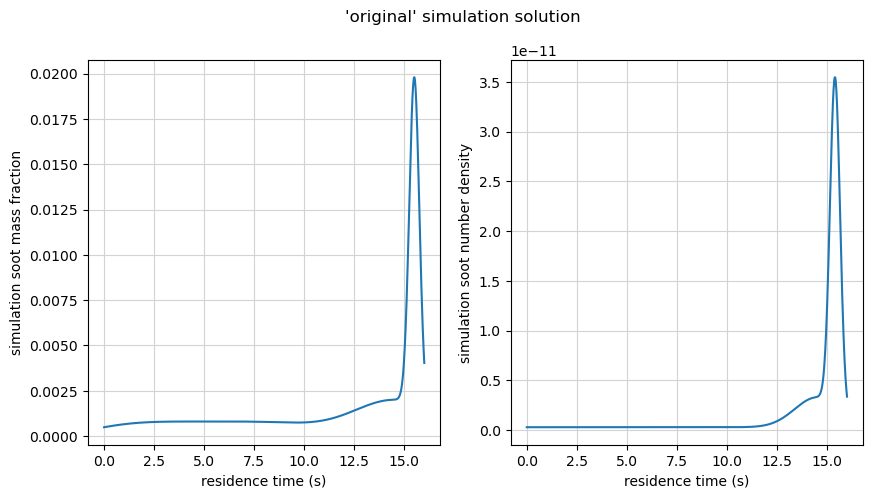

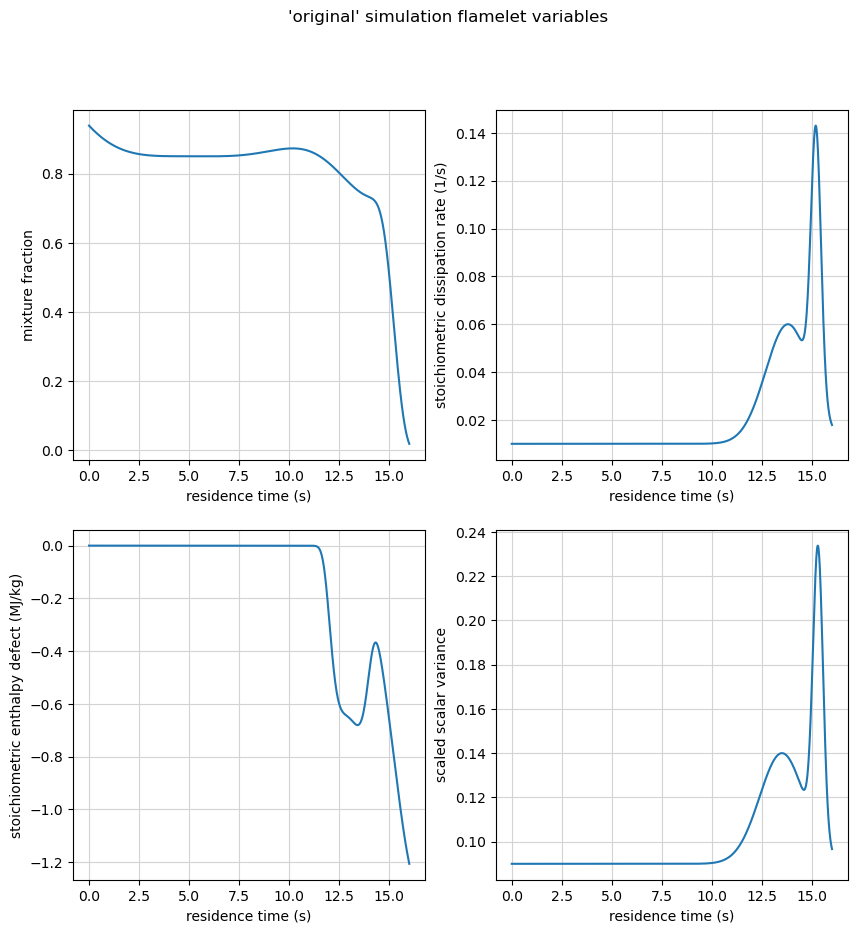

In [11]:
from pytabprops import StateTable, LagrangeInterpolant1D, LagrangeInterpolant4D
from spitfire import apply_mixing_model, PDFSpec

##### 'original' simulation solution quantities:

def z_sim(t): # mixture fraction
    return -(0.4*np.exp(-0.0004*(t-5)**4) + 0.5*np.exp(-0.1*(t-14.5)**2) + 0.9*np.exp(-0.08*(t-17.)**4) - 1.25)

def xst_sim(t): # stoichiometric dissipation rate
    return 0.05*np.exp(-0.4*(t-13.8)**2)+ 0.11*np.exp(-8.*(t-15.2)**2) + 0.01

def gst_sim(t): # stoichiometric enthalpy defect
    return -1.e6*(0.62*np.exp(-0.8*(t-13.)**4) + 1.3*np.exp(-0.3*(t-16.5)**2))

def sv_sim(t): # scaled scalar variance
    return 0.05*np.exp(-0.4*(t-13.5)**2)+ 0.13*np.exp(-8.*(t-15.3)**2) + 0.09

def ys_sim(t): # soot mass fraction
    return 0.0008*np.exp(-0.0008*(t-5)**4) + 0.002*np.exp(-0.1*(t-14.5)**2) + 0.018*np.exp(-8.*(t-15.5)**2) 

def ns_sim(t): # soot number density
    return 1.e-11*(0.3*np.exp(-0.4*(t-14.5)**2) + 3.3*np.exp(-8.*(t-15.4)**2) + 0.03) 

def kys_sim(t): # soot mass fraction kinetics model (source term over density)
    return 0.072*np.exp(-18.*(t-15.5)**2)

def kns_sim(t): # soot number density kinetics model (source term over density)
    return 1.e-11*(1*np.exp(-5.e-8*(t-5.)**8) + 7.5*np.exp(-18.*(t-15.25)**2) + 0.2*np.exp(-1.*(t-12.5)**2) + 0.15*np.exp(-10.*(t-14.5)**2) + 1.*np.exp(-1.*(t-17)**4) - 1.)

t_sim = np.linspace(0., 16., 1000) # residence times

Ys_sim = ys_sim(t_sim)
Ns_sim = ns_sim(t_sim)

tbl_orig_rhs = StateTable()
tbl_orig_rhs.add_entry('Ys', LagrangeInterpolant1D(1, t_sim, Ys_sim, True), ['t'])
tbl_orig_rhs.add_entry('Ns', LagrangeInterpolant1D(1, t_sim, Ns_sim, True), ['t'])
def rys_sim(t): # soot mass fraction time derivative
    return tbl_orig_rhs.derivative('Ys', t)
def rns_sim(t): # soot number density time derivative
    return tbl_orig_rhs.derivative('Ns', t)


fig, ax = plt.subplots(1,2, figsize=(10,5))
ax[0].plot(t_sim, Ys_sim)
ax[1].plot(t_sim, Ns_sim)
ax[0].set_ylabel('simulation soot mass fraction')
ax[1].set_ylabel('simulation soot number density')
for a in ax:
    a.set_xlabel('residence time (s)')
    a.grid(color='lightgray')
plt.suptitle("'original' simulation solution")
plt.show()

fig, ax = plt.subplots(2,2, figsize=(10,10))
ax[0,0].plot(t_sim, z_sim(t_sim))
ax[0,1].plot(t_sim, xst_sim(t_sim))
ax[1,0].plot(t_sim, gst_sim(t_sim)/1.e6)
ax[1,1].plot(t_sim, sv_sim(t_sim))
ax[0,0].set_ylabel('mixture fraction')
ax[0,1].set_ylabel('stoichiometric dissipation rate (1/s)')
ax[1,0].set_ylabel('stoichiometric enthalpy defect (MJ/kg)')
ax[1,1].set_ylabel('scaled scalar variance')
for a in ax.ravel():
    a.set_xlabel('residence time (s)')
    a.grid(color='lightgray')
plt.suptitle("'original' simulation flamelet variables")
plt.show()


We add a scalar variance dimension to our flamelet libraries using `apply_mixing_model` with the presumed clipped-Gaussian PDF and remove any properties not needed for integrating the soot equations. Now our libraries contain all the flamelet variables from the 'original' simulation plotted above.

In [12]:
props_keep = ['density', 'nucl_C2H2', 'coag', 'surf_C2H2', 'surf_OH', 'surf_O2'] # properties needed for soot transport equations

for prop in lib_p0.props:
    if prop not in props_keep:
        lib_p0.remove(prop)

for prop in lib_p1.props:
    if prop not in props_keep:
        lib_p1.remove(prop)

### convolution integrals
varvals = np.linspace(sv_sim(t_sim).min(), sv_sim(t_sim).max(), 4)
tlib_p0 = apply_mixing_model(lib_p0, {'mixture_fraction':PDFSpec('clipgauss', scaled_variance_values=varvals)})
tlib_p1 = apply_mixing_model(lib_p1, {'mixture_fraction':PDFSpec('clipgauss', scaled_variance_values=varvals)})


We can compose source terms given a mass fraction, number density, and tabulated coefficients following the equations in our soot documentation. The `get_soot_source_term_evaluator` function will detect which soot model was used to generate a library based on the species/coefficients present and return the appropriate function for evaluating the source terms for soot mass fraction and soot number density. Similarly, `get_soot_source_term_jacobian_evaluator` returns the Jacobian evaluator. If verbose is True, the soot model detected on the library will be printed. Below, we find the "aksit-moss" model and save off the appropriate functions.

When evaluated, the source term function will return a dictionary of the source terms for the soot number density ('S_Ns') and soot mass fraction ('S_Ys') along with various contributions to those source terms. The 'input_mult_dict' argument can be used to set multipliers for any of the source term coefficients on a library. For example, passing {'surf_c2h2':2} will double the surface growth coefficient for acetylene before evaluating the source terms. More details on the supported soot_src_... functions can be found in the documentation.

In [13]:
src_eval, soot_props = get_soot_source_term_evaluator(tlib_p0)
jac_eval, _ = get_soot_source_term_jacobian_evaluator(tlib_p0)


Detected soot model "aksit-moss" in the table.
Detected soot model "aksit-moss" in the table.


Next we need to create functions for evaluating $K(\bar{\phi}_o)$ and $J(\bar{\phi}_o)$ in our transport equations. This involves evaluating the source term coefficients at the appropriate flamelet variables then evaluating the source terms and Jacobian at those coefficients and solution variables $\bar{\phi}_o$. In order to simplify this evaluation during integration of the soot equations, we build interpolants over the residence time.


In [15]:
def get_interps(library, mult_dict=None):
    inputs = [z_sim(t_sim), xst_sim(t_sim), gst_sim(t_sim), sv_sim(t_sim)] # flamelet variables from 'original' simulation
    inputs_arr = np.array(inputs).T

    ### create table for evaluating source coeffs with flamelet variables
    tbl = StateTable()
    input_names = []
    input_mesh = []
    slice_list = []
    for i,d in enumerate(library.dims):
        input_names.append(d.name)
        vals = d.values
        if 'enthalpy_defect' in input_names[-1]:
            vals = vals[::-1]
            slice_list.append(slice(None, None, -1))
        else:
            slice_list.append(slice(None, None, None))
        input_mesh.append(vals)

    for prop in library.props:
        dval = library[prop].copy()
        dval = dval[tuple(slice_list)]
        interp = LagrangeInterpolant4D(3, 
                                    *input_mesh,
                                    dval.ravel(order='F'), 
                                    True)
        tbl.add_entry(prop, interp, input_names)

    ### at each residence time evaluate the source terms and Jacobian
    soot_coeffs = dict()
    for prop in soot_props:
        soot_coeffs[prop] = tbl.query(prop, *inputs)
    rho = tbl.query('density', *inputs)

    srcs = src_eval(Ns_sim, Ys_sim, **soot_coeffs, input_mult_dict=mult_dict)
    K_Ns = srcs['S_Ns']/rho
    K_Ys = srcs['S_Ys']/rho

    jac = jac_eval(Ns_sim, Ys_sim, **soot_coeffs, input_mult_dict=mult_dict)
    J_NN = jac['dSNs_dNs']/rho
    J_NY = jac['dSNs_dYs']/rho
    J_YN = jac['dSYs_dNs']/rho
    J_YY = jac['dSYs_dYs']/rho

    ### save off interpolants for source term, Jacobian, and density over the residence time
    kind = 1
    K_Ns_interp = interp1d(t_sim, K_Ns, kind=kind)
    K_Ys_interp = interp1d(t_sim, K_Ys, kind=kind)
    J_NN_interp = interp1d(t_sim, J_NN, kind=kind)
    J_NY_interp = interp1d(t_sim, J_NY, kind=kind)
    J_YN_interp = interp1d(t_sim, J_YN, kind=kind)
    J_YY_interp = interp1d(t_sim, J_YY, kind=kind)
    rho_interp = interp1d(t_sim, rho, kind=kind)

    return {'K_Ns':K_Ns_interp, 'K_Ys':K_Ys_interp,
            'J_NN':J_NN_interp, 'J_NY':J_NY_interp,
            'J_YN':J_YN_interp, 'J_YY':J_YY_interp,
            'rho':rho_interp, 'table':tbl}


We will compare solutions for 3 different flamelet models:

1. 100% soot leakage

2. 1% soot leakage

3. 1% soot leakage including a multiplier of 2 on the acetylene surface growth coefficient

We expect these models to show increasing soot levels moving down our list.

In [16]:
### dictionary for saving off solutions for the different models
sol_dict = {
            '100% leakage':            {'interps':get_interps(tlib_p0),                   'color':'k'},
            '1% leakage':              {'interps':get_interps(tlib_p1),                   'color':'r'},
            '1% leakage, 2X surf_c2h2':{'interps':get_interps(tlib_p1, {'surf_c2h2':2.}), 'color':'c'}
           }


Now we can use Spitfire's `odesolve` to integrate the two soot equations. We define `ode_rhs` to compute 

$D_t\bar{\phi} = K(\bar{\phi}_o(t)) - K_o(\bar{\phi}_o(t)) + D_t\bar{\phi}_o(t) + J(\bar{\phi}_o(t))(\bar{\phi} - \bar{\phi}_o(t))$

which, using our interpolants created above, represented with $I$, or the known data/functions from simulation, represented with $F$, looks like

$D_t\bar{\phi} = I_K(t) - F_{K_o}(t) + F_{D_t\bar{\phi}_o}(t) + I_J(t)(\bar{\phi} - F_{\bar{\phi}_o}(t))$.

We also define a postprocessing function `clip` to ensure the solution variables remain positive and bounded. The solutions for $N_s$ and $Y_s$ over time get saved for each of the models in our solution dictionary created above.

In [17]:
def clip(t,q,r,nt):
    soot_number_density = np.min([np.max([q[0], 1.e-16]), 1.e6])
    soot_mass_fraction  = np.min([np.max([q[1], 1.e-16]), 1.])
    return np.array([soot_number_density, soot_mass_fraction])

for sol in sol_dict:
    def ode_rhs(t, phi):
        clipped = clip(None, phi, None, None)
        Ns = clipped[0]
        Ys = clipped[1]
        Ns_sim = ns_sim(t)
        Ys_sim = ys_sim(t)
        diff_Ns = Ns - Ns_sim
        diff_Ys = Ys - Ys_sim

        K_Ns_sim = kns_sim(t)
        K_Ys_sim = kys_sim(t)
        RHS_Ns_sim = rns_sim(t)
        RHS_Ys_sim = rys_sim(t)

        K_Ns = sol_dict[sol]['interps']['K_Ns'](t)
        K_Ys = sol_dict[sol]['interps']['K_Ys'](t)
        J_NN = sol_dict[sol]['interps']['J_NN'](t)
        J_NY = sol_dict[sol]['interps']['J_NY'](t)
        J_YN = sol_dict[sol]['interps']['J_YN'](t)
        J_YY = sol_dict[sol]['interps']['J_YY'](t)

        rhs_Ns = K_Ns - K_Ns_sim + RHS_Ns_sim + J_NN*diff_Ns + J_NY*diff_Ys
        rhs_Ys = K_Ys - K_Ys_sim + RHS_Ys_sim + J_YN*diff_Ns + J_YY*diff_Ys
        return np.array([rhs_Ns, rhs_Ys])

    init = np.array([Ns_sim[0], Ys_sim[0]])
    ts, NsYs = odesolve(ode_rhs, init, save_each_step=True, stop_at_time=t_sim.max(),
                        post_step_callback = clip,
                        step_size=PIController(target_error=1.e-6, first_step=1.e-3, max_step=0.05),
                        maximum_residual=1.e10)
    sol_dict[sol]['t'] = ts
    sol_dict[sol]['Ns'] = NsYs[:,0]
    sol_dict[sol]['Ys'] = NsYs[:,1]


Below we plot the results for soot mass fraction $Y_s$ and number density $N_s$ for each of the soot models. As expected, the 1% leakage model leads to more soot than the 100% leakage since it assumes lower oxidation rates. We also see how doubling the surface growth coefficient leads to further increase in soot mass fraction, as expected. There is little difference among $N_s$ for the models. The only differences come from the contribution of $Y_s$ to $D_t N_s$.


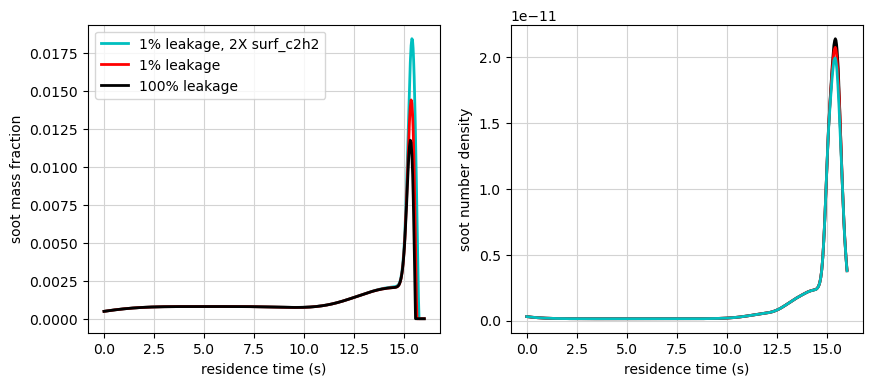

In [18]:
fig, ax = plt.subplots(1,2, figsize=(10,4))
for sol in list(sol_dict.keys())[::-1]:
    ax[0].plot(sol_dict[sol]['t'], sol_dict[sol]['Ys'],'-', linewidth=2, color=sol_dict[sol]['color'], label=sol)
for sol in sol_dict:
    ax[1].plot(sol_dict[sol]['t'], sol_dict[sol]['Ns'],'-', linewidth=2, color=sol_dict[sol]['color'])
ax[0].legend()
for a in ax:
    a.grid(color='lightgray')
    a.set_xlabel('residence time (s)')
ax[0].set_ylabel('soot mass fraction')
ax[1].set_ylabel('soot number density')
plt.show()


The soot volume fraction is another useful quantity to analyze. This can be calculated from

$f_v = Y_s \rho / \rho_s$

where the density of soot $\rho_s = 1800 \ \mathrm{kg}/\mathrm{m}^3$.
This is plotted for the different models below.

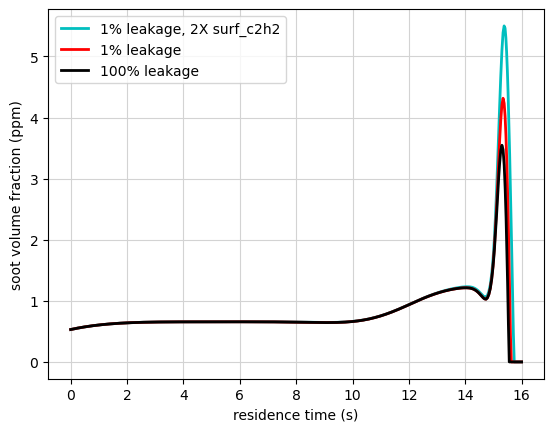

In [19]:
for sol in list(sol_dict.keys())[::-1]:
    fv_ppm = sol_dict[sol]['Ys'] * sol_dict[sol]['interps']['rho'](sol_dict[sol]['t'])/1800.*1.e6
    plt.plot(sol_dict[sol]['t'], fv_ppm, '-', linewidth=2, color=sol_dict[sol]['color'],  label=sol)
plt.legend()
plt.grid(color='lightgray')
plt.xlabel('residence time (s)')
plt.ylabel('soot volume fraction (ppm)')
plt.show()


Finally, we can perform a budget analysis on the source term evaluations for each model. We break each source term down into its components and see which terms have the largest contributions. We find the surface growth is the main contributor for the 1% leakage models, with the multiplier of 2 directly doubling this contribution. The 100% leakage model has larger oxidation, creating more of a balance between it and surface growth. The nucleation and coagulation are the same among the models.


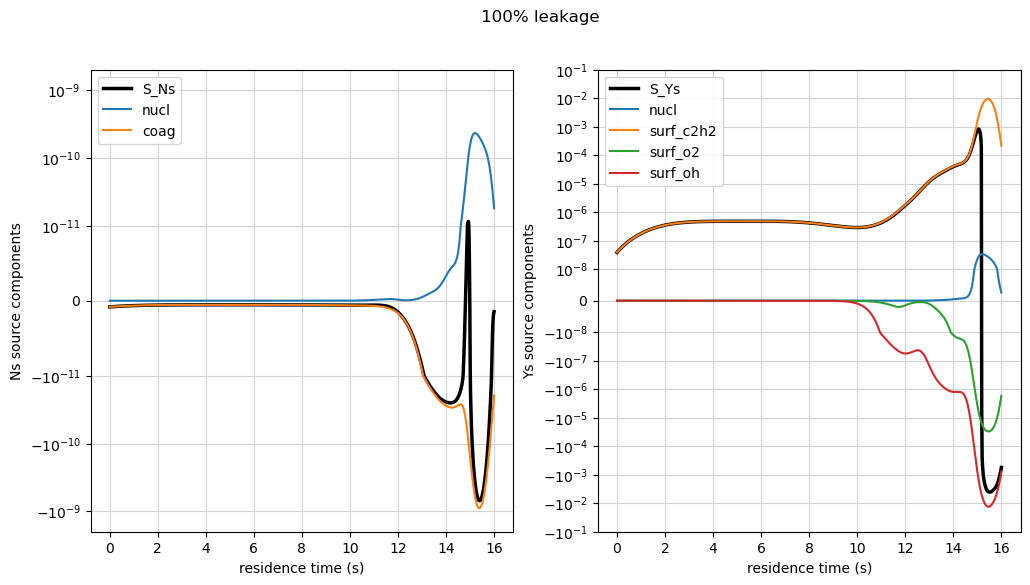

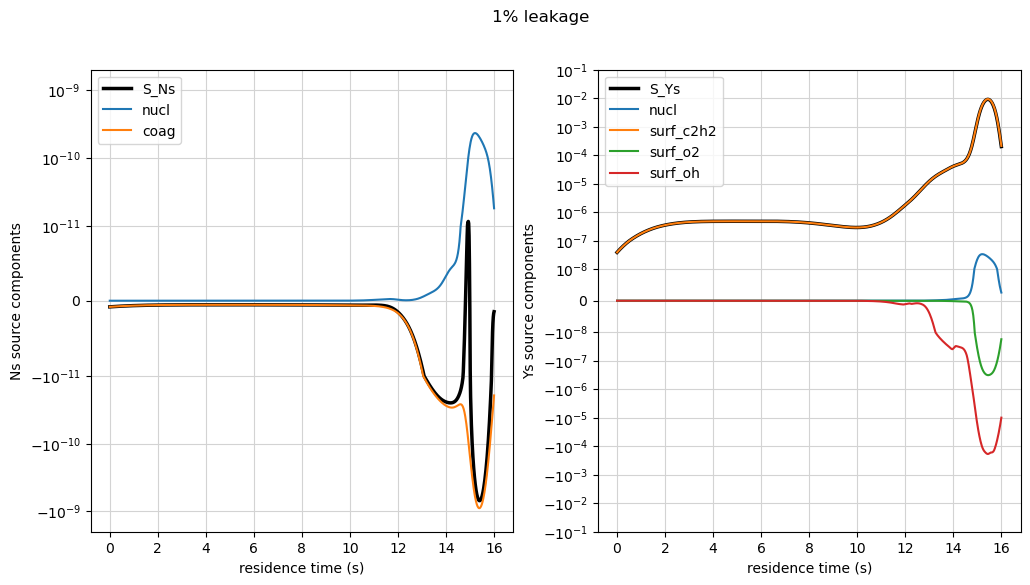

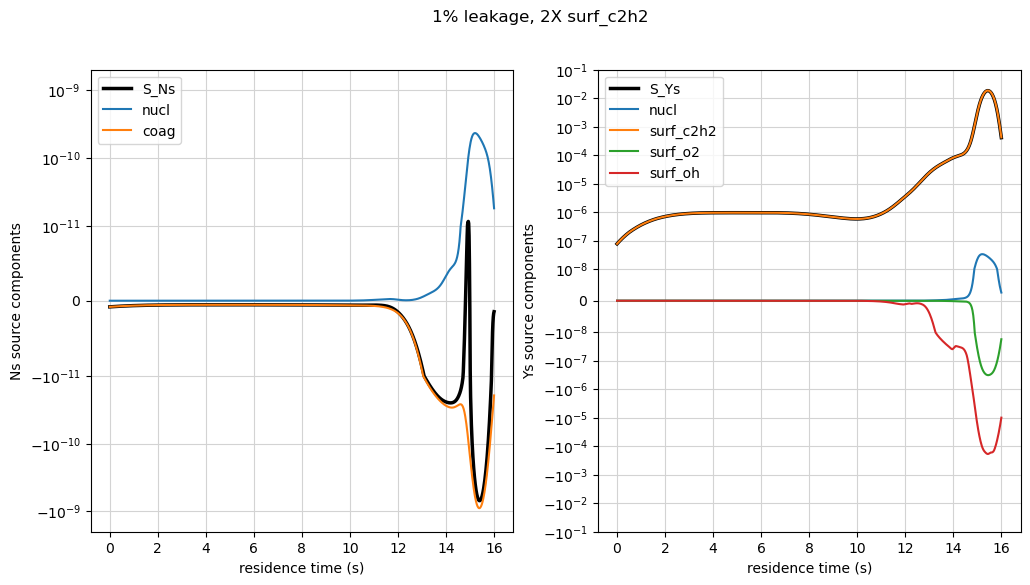

In [20]:
for sol in sol_dict:
    tbl = sol_dict[sol]['interps']['table']
    mult_dict = {'surf_c2h2':2.} if '2X' in sol else None

    inputs = [z_sim(t_sim), xst_sim(t_sim), gst_sim(t_sim), sv_sim(t_sim)]
    inputs_arr = np.array(inputs).T

    nucl_C2H2 = tbl.query('nucl_C2H2', inputs_arr[:,0], inputs_arr[:,1], inputs_arr[:,2], inputs_arr[:,3])
    coag = tbl.query('coag', inputs_arr[:,0], inputs_arr[:,1], inputs_arr[:,2], inputs_arr[:,3])
    surf_C2H2 = tbl.query('surf_C2H2', inputs_arr[:,0], inputs_arr[:,1], inputs_arr[:,2], inputs_arr[:,3])
    surf_O2 = tbl.query('surf_O2', inputs_arr[:,0], inputs_arr[:,1], inputs_arr[:,2], inputs_arr[:,3])
    surf_OH = tbl.query('surf_OH', inputs_arr[:,0], inputs_arr[:,1], inputs_arr[:,2], inputs_arr[:,3])
    rho = tbl.query('density', inputs_arr[:,0], inputs_arr[:,1], inputs_arr[:,2], inputs_arr[:,3])

    src_dict = src_eval(Ns_sim, Ys_sim, nucl_C2H2, coag, surf_C2H2, surf_O2, surf_OH, mult_dict)

    lw = 1.5
    fig, ax = plt.subplots(1,2,figsize=(12,6))
    ax[0].plot(t_sim, src_dict['S_Ns'], 'k-', linewidth=lw+1, label='S_Ns')
    ax[0].plot(t_sim, src_dict['S_Ns_nucl'], linewidth=lw, label='nucl')
    ax[0].plot(t_sim, src_dict['S_Ns_coag'], linewidth=lw, label='coag')
    ax[0].legend()
    ax[0].set_xlabel('residence time (s)')
    ax[0].set_ylabel('Ns source components')
    ax[0].grid(color='lightgray')
    ax[0].set_yscale('symlog', linthresh=1.e-11)
    ax[0].set_ylim([-2.e-9, 2.e-9])

    ax[1].plot(t_sim, src_dict['S_Ys'], 'k-', linewidth=lw+1, label='S_Ys')
    ax[1].plot(t_sim, src_dict['S_Ys_nucl'], linewidth=lw, label='nucl')
    ax[1].plot(t_sim, src_dict['S_Ys_c2h2'], linewidth=lw, label='surf_c2h2')
    ax[1].plot(t_sim, src_dict['S_Ys_o2'], linewidth=lw, label='surf_o2')
    ax[1].plot(t_sim, src_dict['S_Ys_oh'], linewidth=lw, label='surf_oh')
    ax[1].set_yscale('symlog', linthresh=1.e-8)
    ax[1].legend()
    ax[1].set_xlabel('residence time (s)')
    ax[1].set_ylabel('Ys source components')
    ax[1].grid(color='lightgray')
    ax[1].set_ylim([-1.e-1, 1.e-1])

    plt.suptitle(sol)
    plt.show()
